# Notebook 5 — Índice Temporal por Bloques de 20 Segundos

Recorre **todos los MP3** de `SOURCE_DIR` y clasifica cada bloque de 20 s
sin escribir WAVs intermedios.

**Salida:**
- `C:\\temporales\\indice_temporal.csv` — una fila por bloque
- `C:\\temporales\\indice_temporal.xlsx` — hoja principal + resumen por archivo

**Trazabilidad completa**: cada fila tiene `archivo_origen`, `bloque_nro`, `inicio_s`,
`fin_s`, `timestamp` (HH:MM:SS), `label` y `confianza`.

**Ejecutar las celdas de arriba hacia abajo en orden.**
Si se interrumpe, volver a ejecutar: el modo RESUME retoma desde donde quedo.

In [1]:
# ============================================================
# CELDA 1 — CONFIGURACION
# ============================================================

import os
import sys
import warnings
import threading
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings('ignore')

# -- ffmpeg (mismo path que Notebook 1) --
FFMPEG_BIN = r"C:\Users\sukho\AppData\Local\Microsoft\WinGet\Packages\Gyan.FFmpeg_Microsoft.Winget.Source_8wekyb3d8bbwe\ffmpeg-8.1.2-full_build\bin"
if FFMPEG_BIN not in os.environ.get('PATH', ''):
    os.environ['PATH'] = FFMPEG_BIN + os.pathsep + os.environ.get('PATH', '')

from pydub import AudioSegment
AudioSegment.converter = str(Path(FFMPEG_BIN) / 'ffmpeg.exe')
AudioSegment.ffmpeg    = str(Path(FFMPEG_BIN) / 'ffmpeg.exe')
AudioSegment.ffprobe   = str(Path(FFMPEG_BIN) / 'ffprobe.exe')

import subprocess
result = subprocess.run([AudioSegment.converter, '-version'],
                        capture_output=True, text=True)
print('ffmpeg OK' if result.returncode == 0 else 'ERROR: ffmpeg no encontrado')

# -- Rutas --
SOURCE_DIR     = r"C:\Compartida Fast\CintasTestigo"
OUTPUT_CSV     = r"C:\temporales\indice_temporal.csv"
OUTPUT_XLSX    = r"C:\temporales\indice_temporal.xlsx"
# Modelo entrenado (Notebook 3); si no existe usa heuristicas+PANNs
MODEL_PATH     = r"C:\temporales\modelos\clasificador_radio_v1.pth"

# -- Parametros de bloques --
BLOCK_S        = 20        # duracion de cada bloque en segundos
OVERLAP_S      = 0         # solapamiento entre bloques (0 = sin solapamiento)
MIN_BLOCK_S    = 5         # bloques mas cortos que esto se descartan (ultimo trozo)
SAMPLE_RATE    = 32_000    # Hz para heuristicas / modelo
PANNS_SR       = 32_000    # Hz que espera CNN14

# -- Rendimiento --
MAX_WORKERS    = 8         # threads para I/O paralelo
CHECKPOINT_N   = 50        # guardar CSV cada N archivos
RESUME         = True      # True = saltar archivos ya procesados

# -- Confianza minima para aceptar la etiqueta (si no -> 'indefinido') --
MIN_CONFIDENCE = 0.45

os.makedirs(Path(OUTPUT_CSV).parent, exist_ok=True)
print('Configuracion lista')
print(f'  Source  : {SOURCE_DIR}')
print(f'  CSV     : {OUTPUT_CSV}')
print(f'  Excel   : {OUTPUT_XLSX}')
print(f'  Bloque  : {BLOCK_S} s (overlap={OVERLAP_S} s)')
print(f'  Modelo  : {MODEL_PATH}')


ffmpeg OK
Configuracion lista
  Source  : C:\Compartida Fast\CintasTestigo
  CSV     : C:\temporales\indice_temporal.csv
  Excel   : C:\temporales\indice_temporal.xlsx
  Bloque  : 20 s (overlap=0 s)
  Modelo  : C:\temporales\modelos\clasificador_radio_v1.pth


In [2]:
# ============================================================
# CELDA 2 — CARGAR CLASIFICADOR
# Intenta cargar el modelo entrenado (Notebook 3).
# Si no existe o falla, usa heuristicas espectrales + PANNs.
# ============================================================

import librosa
import librosa.display

AUDIOSET_MAP = {
    'Music': 'musica', 'Musical': 'musica', 'Singing': 'musica',
    'Song': 'musica', 'Jingle': 'cortina', 'Ringtone': 'cortina',
    'Speech': 'noticias', 'Narration': 'noticias', 'Monologue': 'noticias',
    'Conversation': 'entrevistas', 'Discussion': 'entrevistas',
    'Interview': 'entrevistas', 'Crowd': 'deportes', 'Cheering': 'deportes',
    'Sports': 'deportes', 'Silence': 'indefinido', 'Noise': 'indefinido',
}

def map_audioset(label_scores):
    best_cat, best_score = 'indefinido', 0.0
    for label, score in label_scores[:5]:
        for kw, cat in AUDIOSET_MAP.items():
            if kw.lower() in label.lower() and score > best_score:
                best_score = score; best_cat = cat; break
    return best_cat, round(float(best_score), 3)

USE_MODEL = False
model = None
IDX_TO_LABEL = None
LABEL_TO_IDX = None
model_cfg = None

if Path(MODEL_PATH).exists():
    try:
        import torch
        import torchaudio
        import torchaudio.transforms as T
        import torch.nn.functional as F
        import timm

        device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        checkpoint   = torch.load(MODEL_PATH, map_location=device)
        LABEL_TO_IDX = checkpoint['label_to_idx']
        IDX_TO_LABEL = checkpoint['idx_to_label']
        model_cfg    = checkpoint['config']
        N_CLASES     = len(LABEL_TO_IDX)

        model = timm.create_model('efficientnet_b0', pretrained=False, num_classes=N_CLASES)
        model.load_state_dict(checkpoint['model_state'])
        model = model.to(device); model.eval()

        USE_MODEL = True
        print(f'Modelo cargado ({device}) | epoca {checkpoint["epoch"]} | clases: {list(LABEL_TO_IDX.keys())}')
    except Exception as e:
        print(f'Error cargando modelo: {e}')
        print('Usando heuristicas + PANNs como fallback.')
else:
    print(f'Modelo no encontrado en {MODEL_PATH}')
    print('Usando heuristicas espectrales + PANNs como fallback.')

USE_PANNS = False
panns_model = None
if not USE_MODEL:
    try:
        import torch
        from panns_inference import AudioTagging, labels as asl
        _device_str = 'cuda' if torch.cuda.is_available() else 'cpu'
        panns_model = AudioTagging(checkpoint_path=None, device=_device_str)
        USE_PANNS = True
        print(f'PANNs cargado ({_device_str})')
    except Exception as e:
        print(f'PANNs no disponible: {e}')
        print('Solo heuristicas espectrales.')

print(f'\nModo de clasificacion: {"MODELO ENTRENADO" if USE_MODEL else ("PANNS + heuristicas" if USE_PANNS else "Solo heuristicas")}')


Modelo cargado (cuda) | epoca 13 | clases: ['deportes', 'entrevistas', 'locutor', 'musica']

Modo de clasificacion: MODELO ENTRENADO


In [3]:
# ============================================================
# CELDA 3 — FUNCIONES DE CLASIFICACION DE UN BLOQUE
# Trabaja sobre arrays numpy en memoria (sin WAVs en disco)
# ============================================================

def pydub_to_numpy(segment, target_sr=SAMPLE_RATE):
    """Convierte un AudioSegment de pydub a numpy float32 mono."""
    seg = segment.set_channels(1).set_frame_rate(target_sr)
    samples = np.array(seg.get_array_of_samples(), dtype=np.float32)
    max_val = float(2 ** (seg.sample_width * 8 - 1))
    return samples / max_val


def heuristic_classify(y, sr=SAMPLE_RATE):
    """Heuristicas espectrales. Retorna (label, confianza)."""
    if len(y) < sr:
        return 'indefinido', 0.5
    try:
        score = 0.0
        try:
            tempo, beats = librosa.beat.beat_track(y=y, sr=sr)
            tempo_val = float(tempo) if np.isscalar(tempo) else float(tempo[0])
            beat_regularity = (
                1.0 - np.std(np.diff(beats)) / (np.mean(np.diff(beats)) + 1e-6)
                if len(beats) > 2 else 0.0
            )
            if beat_regularity > 0.7:  score += 0.35
            elif beat_regularity > 0.5: score += 0.20
            if 50 < tempo_val < 200:   score += 0.20
            if len(beats) > 10:        score += 0.10
        except Exception:
            pass

        y_harm, _ = librosa.effects.hpss(y)
        harm_ratio = float(np.mean(y_harm ** 2) / (np.mean(y ** 2) + 1e-8))
        if harm_ratio > 0.6:  score += 0.25
        elif harm_ratio > 0.4: score += 0.12

        chroma = librosa.feature.chroma_stft(y=y, sr=sr)
        chroma_std = float(np.mean(np.std(chroma, axis=1)))
        if chroma_std > 0.15: score += 0.10

        if score >= 0.45:
            return 'musica', round(min(score, 0.97), 2)
        return None, round(1.0 - score, 2)
    except Exception:
        return None, 0.0


def classify_block_model(y, sr=SAMPLE_RATE):
    """Clasifica con el modelo EfficientNet entrenado."""
    import torch
    import torchaudio.transforms as T
    import torch.nn.functional as F

    SR   = model_cfg['sample_rate']
    NFFT = model_cfg['n_fft']
    HOP  = model_cfg['hop_length']
    MELS = model_cfg['n_mels']
    SZ   = model_cfg['img_size']

    if sr != SR:
        y = librosa.resample(y, orig_sr=sr, target_sr=SR)
        sr = SR

    wf = torch.from_numpy(y).unsqueeze(0)
    mel_t = T.MelSpectrogram(sample_rate=SR, n_fft=NFFT, hop_length=HOP, n_mels=MELS, f_max=15000)
    db_t  = T.AmplitudeToDB(top_db=80)

    mel = db_t(mel_t(wf))
    mn, mx = mel.min(), mel.max()
    if mx > mn:
        mel = 2.0 * (mel - mn) / (mx - mn) - 1.0
    mel_r = F.interpolate(mel.unsqueeze(0), size=(SZ, SZ), mode='bilinear', align_corners=False).squeeze(0)
    inp = mel_r.repeat(3, 1, 1).unsqueeze(0).to(device)

    with torch.no_grad():
        logits = model(inp)
    probs = F.softmax(logits, dim=1).cpu().numpy()[0]
    idx   = probs.argmax()
    conf  = float(probs[idx])
    label = IDX_TO_LABEL[idx] if conf >= MIN_CONFIDENCE else 'indefinido'
    return label, round(conf, 3)


def classify_block_panns(y, sr=SAMPLE_RATE):
    """Clasifica con PANNs CNN14."""
    lbl_h, conf_h = heuristic_classify(y, sr)
    if lbl_h == 'musica' and conf_h >= 0.80:
        return lbl_h, conf_h, 'heuristica'

    MAX_S = PANNS_SR * BLOCK_S
    y_p = librosa.resample(y, orig_sr=sr, target_sr=PANNS_SR) if sr != PANNS_SR else y
    if len(y_p) >= MAX_S:
        y_p = y_p[:MAX_S]
    else:
        y_p = np.pad(y_p, (0, MAX_S - len(y_p)))

    import torch
    audio_batch = y_p[np.newaxis, :]
    with torch.no_grad():
        clip_out, _ = panns_model.inference(audio_batch)
    top_idx = np.argsort(clip_out[0])[::-1][:10]
    label_scores = [(asl[j], float(clip_out[0][j])) for j in top_idx]
    lbl_p, conf_p = map_audioset(label_scores)

    if lbl_h == 'musica' and lbl_p == 'musica':
        return 'musica', min(0.97, (conf_h + conf_p) / 2 + 0.1), 'panns'
    return lbl_p, conf_p, 'panns'


def classify_block(y, sr=SAMPLE_RATE):
    """
    Clasifica un bloque de audio (numpy array mono float32).
    Retorna (label, confianza, fuente).
    """
    if USE_MODEL:
        try:
            lbl, conf = classify_block_model(y, sr)
            return lbl, conf, 'modelo'
        except Exception:
            pass
    if USE_PANNS:
        try:
            return classify_block_panns(y, sr)
        except Exception:
            pass
    lbl, conf = heuristic_classify(y, sr)
    if lbl is None:
        lbl = 'indefinido'
    return lbl, conf, 'heuristica'


def seconds_to_hhmmss(s):
    s = int(s)
    return f"{s // 3600:02d}:{(s % 3600) // 60:02d}:{s % 60:02d}"


print('Funciones de clasificacion listas')
print(f'  USE_MODEL={USE_MODEL}, USE_PANNS={USE_PANNS}')


Funciones de clasificacion listas
  USE_MODEL=True, USE_PANNS=False


In [4]:
# ============================================================
# CELDA 4 — ESCANEAR ARCHIVOS MP3
# ============================================================

all_mp3s = sorted(Path(SOURCE_DIR).rglob("*.mp3"))
all_mp3s += sorted(Path(SOURCE_DIR).rglob("*.MP3"))
all_mp3s = list(set(all_mp3s))

print(f"Total archivos MP3 encontrados: {len(all_mp3s)}")
total_gb = sum(f.stat().st_size for f in all_mp3s) / (1024**3)
print(f"Tamano total: {total_gb:.2f} GB")


Total archivos MP3 encontrados: 275
Tamano total: 8.68 GB


In [5]:
# ============================================================
# CELDA 5 — CARGAR PROGRESO ANTERIOR (RESUME)
# ============================================================

csv_path = Path(OUTPUT_CSV)

if RESUME and csv_path.exists() and csv_path.stat().st_size > 0:
    try:
        existing_df = pd.read_csv(OUTPUT_CSV)
        already_processed = set(existing_df['archivo_origen'].unique())
        existing_records = existing_df.to_dict('records')
        print(f"Retomando: {len(already_processed)} archivos ya procesados, "
              f"{len(existing_df):,} bloques en indice")
    except Exception as e:
        print(f"Advertencia: no se pudo leer el CSV ({e}). Iniciando desde cero.")
        already_processed = set()
        existing_records = []
else:
    already_processed = set()
    existing_records = []
    print("Iniciando desde cero")

pending_mp3s = [f for f in all_mp3s if str(f) not in already_processed]
print(f"Archivos pendientes: {len(pending_mp3s):,}")


Retomando: 260 archivos ya procesados, 23,533 bloques en indice
Archivos pendientes: 16


In [6]:
# ============================================================
# CELDA 6 — LOOP PRINCIPAL DE CLASIFICACION POR BLOQUES
#
# Para cada archivo:
#   1. Carga el MP3 completo con pydub (sin escribir WAVs)
#   2. Lo divide en bloques de BLOCK_S segundos
#   3. Clasifica cada bloque en memoria
#   4. Acumula filas con trazabilidad temporal
#   5. Checkpoint cada CHECKPOINT_N archivos
# ============================================================

from tqdm.notebook import tqdm
from concurrent.futures import ThreadPoolExecutor, as_completed

STEP_MS      = int((BLOCK_S - OVERLAP_S) * 1000)
BLOCK_MS     = int(BLOCK_S * 1000)
MIN_BLOCK_MS = int(MIN_BLOCK_S * 1000)

new_records     = []
errors          = []
records_lock    = threading.Lock()
checkpoint_lock = threading.Lock()
completed_count = 0


def checkpoint_save():
    """Guarda el CSV acumulado hasta ahora (thread-safe)."""
    with checkpoint_lock:
        all_so_far = existing_records + new_records
        pd.DataFrame(all_so_far).to_csv(OUTPUT_CSV, index=False)


def procesar_mp3(mp3_path):
    """
    Carga un MP3, lo divide en bloques de BLOCK_S segundos y
    clasifica cada bloque en memoria.
    Retorna (list_of_records, error_dict|None).
    """
    try:
        audio = AudioSegment.from_mp3(str(mp3_path))
        total_ms    = len(audio)
        archivo_str = str(mp3_path)
        nombre_str  = mp3_path.name

        local_records = []
        bloque_nro = 0
        pos_ms = 0

        while pos_ms < total_ms:
            end_ms = min(pos_ms + BLOCK_MS, total_ms)
            dur_ms = end_ms - pos_ms

            if dur_ms < MIN_BLOCK_MS:
                break

            seg = audio[pos_ms:end_ms]
            y   = pydub_to_numpy(seg, target_sr=SAMPLE_RATE)

            label, conf, fuente = classify_block(y, SAMPLE_RATE)

            inicio_s = round(pos_ms / 1000, 3)
            fin_s    = round(end_ms / 1000, 3)

            local_records.append({
                'archivo_origen' : archivo_str,
                'nombre_archivo' : nombre_str,
                'bloque_nro'     : bloque_nro,
                'inicio_s'       : inicio_s,
                'fin_s'          : fin_s,
                'duracion_s'     : round(dur_ms / 1000, 3),
                'timestamp'      : seconds_to_hhmmss(inicio_s),
                'label'          : label,
                'confianza'      : round(conf, 3),
                'fuente'         : fuente,
            })

            bloque_nro += 1
            pos_ms += STEP_MS

        return local_records, None

    except Exception as e:
        return [], {'archivo': str(mp3_path), 'error': str(e)}


with ThreadPoolExecutor(max_workers=MAX_WORKERS) as executor:
    futures = {executor.submit(procesar_mp3, p): p for p in pending_mp3s}

    with tqdm(total=len(pending_mp3s), desc="Clasificando", unit="archivo") as pbar:
        for future in as_completed(futures):
            recs, err = future.result()

            with records_lock:
                if err:
                    errors.append(err)
                else:
                    new_records.extend(recs)
                completed_count += 1
                do_checkpoint = (completed_count % CHECKPOINT_N == 0)

            if do_checkpoint:
                checkpoint_save()

            pbar.update(1)

# Guardado final
all_records = existing_records + new_records
df_index = pd.DataFrame(all_records)
df_index.to_csv(OUTPUT_CSV, index=False)

print(f"\nClasificacion completa")
print(f"  Archivos procesados : {completed_count:,}")
print(f"  Total bloques       : {len(df_index):,}")
print(f"  Errores             : {len(errors)}")
print(f"  CSV guardado        : {OUTPUT_CSV}")

if errors:
    err_df = pd.DataFrame(errors)
    err_path = str(Path(OUTPUT_CSV).parent / 'errores_indice_temporal.csv')
    err_df.to_csv(err_path, index=False)
    print(f"  Errores guardados   : {err_path}")
    print(err_df.head(10))


Clasificando:   0%|          | 0/16 [00:00<?, ?archivo/s]


Clasificacion completa
  Archivos procesados : 16
  Total bloques       : 23,533
  Errores             : 3
  CSV guardado        : C:\temporales\indice_temporal.csv
  Errores guardados   : C:\temporales\errores_indice_temporal.csv
                                             archivo  \
0  C:\Compartida Fast\CintasTestigo\20260709-0900...   
1  C:\Compartida Fast\CintasTestigo\20260723-0900...   
2  C:\Compartida Fast\CintasTestigo\20260713-0900...   

                                               error  
0  Decoding failed. ffmpeg returned error code: 3...  
1  Decoding failed. ffmpeg returned error code: 3...  
2  Decoding failed. ffmpeg returned error code: 3...  


In [7]:
# ============================================================
# CELDA 7 — EXPORTAR EXCEL CON MULTIPLES HOJAS
# ============================================================

df_index = pd.read_csv(OUTPUT_CSV)

resumen_archivo = (
    df_index
    .groupby(['archivo_origen', 'nombre_archivo', 'label'])
    .agg(
        bloques=('bloque_nro', 'count'),
        duracion_s=('duracion_s', 'sum'),
        confianza_prom=('confianza', 'mean'),
    )
    .reset_index()
)
resumen_archivo['duracion_min'] = (resumen_archivo['duracion_s'] / 60).round(2)
resumen_archivo['confianza_prom'] = resumen_archivo['confianza_prom'].round(3)
resumen_archivo = resumen_archivo.sort_values(
    ['archivo_origen', 'duracion_s'], ascending=[True, False]
)

resumen_global = (
    df_index
    .groupby('label')
    .agg(
        bloques=('bloque_nro', 'count'),
        duracion_horas=('duracion_s', lambda x: round(x.sum() / 3600, 2)),
        confianza_prom=('confianza', lambda x: round(x.mean(), 3)),
    )
    .reset_index()
    .sort_values('bloques', ascending=False)
)

with pd.ExcelWriter(OUTPUT_XLSX, engine='openpyxl') as writer:
    df_index.to_excel(writer, sheet_name='Indice_Temporal', index=False)
    resumen_archivo.to_excel(writer, sheet_name='Resumen_por_Archivo', index=False)
    resumen_global.to_excel(writer, sheet_name='Resumen_Global', index=False)

print(f"Excel exportado: {OUTPUT_XLSX}")
print(f"  Hoja 'Indice_Temporal'    : {len(df_index):,} filas")
print(f"  Hoja 'Resumen_por_Archivo': {len(resumen_archivo):,} filas")
print(f"  Hoja 'Resumen_Global'     : {len(resumen_global):,} filas")
print()
print("Distribucion global:")
print(resumen_global.to_string(index=False))


Excel exportado: C:\temporales\indice_temporal.xlsx
  Hoja 'Indice_Temporal'    : 23,533 filas
  Hoja 'Resumen_por_Archivo': 1,536 filas
  Hoja 'Resumen_Global'     : 6 filas

Distribucion global:
      label  bloques  duracion_horas  confianza_prom
     musica     8732           48.50           0.999
 publicidad     6245           34.69           0.999
   deportes     4644           25.80           0.999
   noticias     2101           11.67           1.000
entrevistas     1018            5.65           0.998
    cortina      793            4.40           0.999


In [8]:
# ============================================================
# CELDA 8 — INSPECCIONAR UN ARCHIVO (linea de tiempo tabla)
# ============================================================

ARCHIVO_INSPECCION = r"C:\Compartida Fast\CintasTestigo\20260716-093000.mp3"   # <-- Cambiar por una ruta real

df_index = pd.read_csv(OUTPUT_CSV)
df_arch = df_index[df_index['archivo_origen'] == ARCHIVO_INSPECCION].copy()

if len(df_arch) == 0:
    print(f"Archivo no encontrado en el indice: {ARCHIVO_INSPECCION}")
    print("Asegurate de que el path sea exactamente igual al de la columna 'archivo_origen'.")
else:
    dur_total = df_arch['duracion_s'].sum()
    print(f"{Path(ARCHIVO_INSPECCION).name}")
    print(f"  Bloques: {len(df_arch)} | Duracion total indexada: {seconds_to_hhmmss(dur_total)}")
    print()
    display_cols = ['bloque_nro', 'timestamp', 'fin_s', 'duracion_s', 'label', 'confianza', 'fuente']
    print(df_arch[display_cols].to_string(index=False))


20260716-093000.mp3
  Bloques: 90 | Duracion total indexada: 00:29:59

 bloque_nro timestamp    fin_s  duracion_s       label  confianza fuente
          0  00:00:00   20.000      20.000      musica      1.000 modelo
          1  00:00:20   40.000      20.000  publicidad      1.000 modelo
          2  00:00:40   60.000      20.000  publicidad      1.000 modelo
          3  00:01:00   80.000      20.000      musica      1.000 modelo
          4  00:01:20  100.000      20.000  publicidad      1.000 modelo
          5  00:01:40  120.000      20.000    deportes      1.000 modelo
          6  00:02:00  140.000      20.000      musica      0.998 modelo
          7  00:02:20  160.000      20.000     cortina      1.000 modelo
          8  00:02:40  180.000      20.000    deportes      1.000 modelo
          9  00:03:00  200.000      20.000      musica      1.000 modelo
         10  00:03:20  220.000      20.000    deportes      1.000 modelo
         11  00:03:40  240.000      20.000    deporte

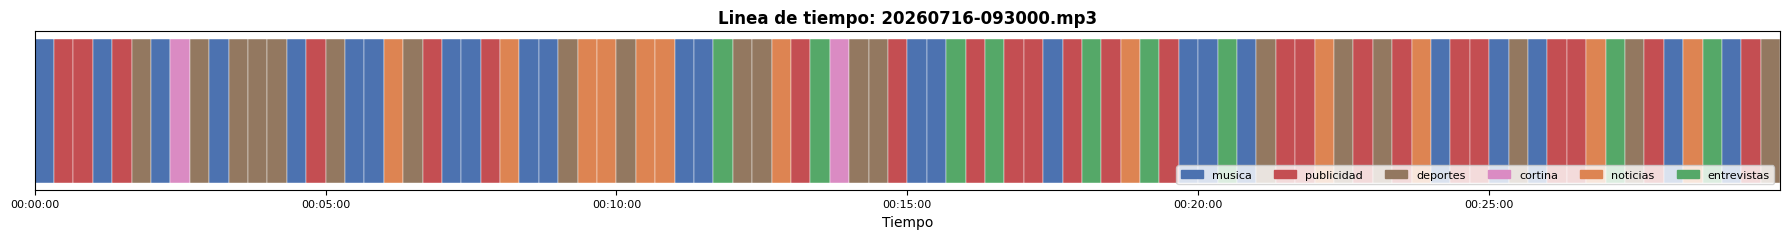

Imagen guardada: C:\temporales\timeline_20260716-093000.png


In [9]:
# ============================================================
# CELDA 9 — GRAFICO DE LINEA DE TIEMPO (1 archivo)
# ============================================================

import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

df_index = pd.read_csv(OUTPUT_CSV)
df_arch = df_index[df_index['archivo_origen'] == ARCHIVO_INSPECCION].copy()

if len(df_arch) == 0:
    print("Sin datos. Ejecutar celda 8 primero con un archivo valido.")
else:
    COLORES = {
        'musica'      : '#4c72b0',
        'noticias'    : '#dd8452',
        'entrevistas' : '#55a868',
        'publicidad'  : '#c44e52',
        'clima'       : '#8172b3',
        'deportes'    : '#937860',
        'cortina'     : '#da8bc3',
        'indefinido'  : '#cccccc',
    }

    dur_total = df_arch['fin_s'].max()
    fig, ax = plt.subplots(figsize=(18, 2.5))

    for _, row in df_arch.iterrows():
        color = COLORES.get(row['label'], '#cccccc')
        ax.barh(y=0, width=row['duracion_s'], left=row['inicio_s'],
                height=0.6, color=color, edgecolor='white', linewidth=0.3)

    tick_interval = 300
    ticks = range(0, int(dur_total) + tick_interval, tick_interval)
    ax.set_xticks(list(ticks))
    ax.set_xticklabels([seconds_to_hhmmss(t) for t in ticks], fontsize=8)
    ax.set_xlim(0, dur_total)
    ax.set_yticks([])
    ax.set_title(f"Linea de tiempo: {Path(ARCHIVO_INSPECCION).name}",
                 fontsize=12, fontweight='bold')
    ax.set_xlabel('Tiempo')

    labels_presentes = df_arch['label'].unique()
    parches = [mpatches.Patch(color=COLORES.get(l, '#cccccc'), label=l)
               for l in labels_presentes]
    ax.legend(handles=parches, loc='lower right', fontsize=8,
              framealpha=0.8, ncol=len(parches))

    plt.tight_layout()
    out_img = str(Path(OUTPUT_CSV).parent / f"timeline_{Path(ARCHIVO_INSPECCION).stem}.png")
    plt.savefig(out_img, dpi=120, bbox_inches='tight')
    plt.show()
    print(f"Imagen guardada: {out_img}")
